# How many cores for the pipeline? (TNG50-2)

The pipeline (`tools/run_parallel_illustris.py --cores N`) runs a `multiprocessing.Pool`
of **N worker processes**, each extracting one whole halo (363 skewers, `HCD_only`).
More workers is not always faster: they all read the same snapshot from one disk
and share memory bandwidth.

Here, for each N, we run **N halos with N workers** using the pipeline's own worker
(`time_pipeline_workers.py` -> `process_single_halo`) and measure:
* **throughput** (halos per hour), which is what sets the time of a full run;
* the time of each halo (slows down when workers compete);
* the peak memory.

**OpenMP threads.** The pipeline does not set `OMP_NUM_THREADS`, so each worker opens one
thread per machine core (32): with N = 20 that is 640 threads on 32 cores.
`OMP_SETTINGS` compares `1` thread per worker with `0` = unset (the pipeline today).

Reference: the production run of TNG50-2 (637 halos, 20 cores) took 304.8 min.

In [1]:
import os
import sys
import json
import subprocess
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

%matplotlib widget
%load_ext autoreload
%autoreload 2

# Same plotting style as the other benchmark notebooks
plt.rc('font', family='serif', size=12)
plt.rcParams.update({
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

In [2]:
# ==============================================================================
# CELL 1: CONFIGURATION
# ==============================================================================
# Project root = the folder that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
BENCH_DIR = PROJ_ROOT / "benchmarks"

SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"
SNAP_NUM  = 25

# Workers to test (the machine has 32 cores; N = 32 left out, since it leaves
# no core free for the rest of the machine). Each point runs N halos with N
# workers, so it takes about one halo time (~10 min on TNG50-2), more if the
# workers slow each other down. Remove points to make the scan shorter.
N_LIST = [1, 2, 4, 8, 12, 16, 20, 24, 28]

# OpenMP threads per worker: 1, and 0 = unset (how the pipeline runs today).
# Each setting is a full scan of N_LIST.
OMP_SETTINGS = [1, 0]

# Halos: drawn from ONE mass bin, so that every halo costs about the same and
# the points are comparable. The same list is used for every N (first N ids).
LOG_MASS_MIN, LOG_MASS_MAX = 11.0, 11.5
SEED = 42

# One halo extracted before the scan and not recorded: the first run pays
# the cold disk cache, which would bias the first point.
WARMUP = True

# Reference for the projection: halos per realization in the production runs
N_HALOS_PRODUCTION = 637

RERUN = False      # False: reuse the .json files already in RESULTS_DIR

RESULTS_DIR = BENCH_DIR / "results" / f"{SIM_NAME}_cores_scaling"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("results :", RESULTS_DIR)

results : /home/vroberto/FakeSpectra_DLAs/benchmarks/results/TNG50-2_cores_scaling


## 1. Pick the halos

In [3]:
# ==============================================================================
# CELL 2: HALOS FROM ONE MASS BIN
# ==============================================================================
group_dir = Path(BASE_PATH) / f"groups_{SNAP_NUM:03d}"
group_files = sorted(group_dir.glob(f"fof_subhalo_tab_{SNAP_NUM:03d}.*.hdf5"),
                     key=lambda p: int(p.name.split(".")[-2]))   # numeric order = global index order

with h5py.File(group_files[0], "r") as f:
    hubble_h = float(f["Header"].attrs["HubbleParam"])

# Group_M_Crit200 of every FoF group, in Msun
mass = []
for gf in tqdm(group_files, desc="group files"):
    with h5py.File(gf, "r") as f:
        if "Group" in f and "Group_M_Crit200" in f["Group"]:
            mass.append(f["Group/Group_M_Crit200"][:])
log_mass = np.log10(np.maximum(np.concatenate(mass), 1e-10) * 1e10 / hubble_h)

# Random halos in the bin: 32 for the scan, +1 for the warm-up. Kept at 32
# (the first scan went up to N = 32) so that the halo list, and so the points
# already on disk, do not change when N_LIST changes
in_bin = np.flatnonzero((log_mass >= LOG_MASS_MIN) & (log_mass < LOG_MASS_MAX))
rng = np.random.default_rng(SEED)
chosen = rng.choice(in_bin, size=32 + 1, replace=False)
warmup_id, scan_ids = chosen[0], chosen[1:]

print(f"{len(in_bin)} halos in [{LOG_MASS_MIN}, {LOG_MASS_MAX}); "
      f"using {len(scan_ids)} (+1 warm-up)")

group files: 100%|██████████| 128/128 [00:00<00:00, 934.00it/s]

698 halos in [11.0, 11.5); using 32 (+1 warm-up)


## 2. Run the scan
Each point is a fresh `python time_pipeline_workers.py ...`. Total time is roughly
`len(N_LIST) x len(OMP_SETTINGS) x 10 min`; finished points are kept on disk, so the
cell can be stopped and restarted.

In [ ]:
# ==============================================================================
# CELL 3: RUN EVERY (OMP setting, N) POINT
# ==============================================================================
def run_point(n_workers, omp, ids, out):
    # Run `ids` halos with `n_workers` processes; the result goes to `out` (.json).
    # Returns the wall time in minutes (None if the point was already on disk).
    if out.exists() and not RERUN:
        return None
    ids_file = out.with_suffix(".npy")
    np.save(ids_file, np.asarray(ids))
    cmd = [sys.executable, str(BENCH_DIR / "time_pipeline_workers.py"),
           "--sim", SIM_NAME, "--snap", str(SNAP_NUM), "--halo_ids", str(ids_file),
           "--n_workers", str(n_workers), "--omp_threads", str(omp), "--out", str(out)]
    # cwd = RESULTS_DIR: the pipeline module writes its error log in the cwd
    res = subprocess.run(cmd, capture_output=True, text=True, cwd=RESULTS_DIR)
    if res.returncode != 0:
        print(res.stderr[-3000:])
        raise RuntimeError(f"N={n_workers}, omp={omp} failed")
    return json.loads(res.stdout.splitlines()[-1])["wall"] / 60

# Every point of the scan, in the order it runs: (label, n_workers, omp, halo ids, output)
points = []
if WARMUP:
    points.append(("warm-up", 1, 1, [warmup_id], RESULTS_DIR / "warmup.json"))
for omp in OMP_SETTINGS:
    for n in N_LIST:
        points.append((f"N={n} omp={omp}", n, omp, scan_ids[:n],
                       RESULTS_DIR / f"N{n:02d}_omp{omp}.json"))

# One bar step per point; the description shows the point running now and
# the postfix the wall time of the last one ("cached" = read from disk)
bar = tqdm(points, desc="scan")
for label, n, omp, ids, out in bar:
    bar.set_description(f"running {label}")
    wall = run_point(n, omp, ids, out)
    bar.set_postfix(last=label, wall="cached" if wall is None else f"{wall:.1f} min")
bar.close()

running N=28 omp=0: 100%|██████████| 19/19 [1:10:54<00:00, 223.93s/it, last=N=28 omp=0, wall=14.1 min]


In [5]:
# ==============================================================================
# CELL 4: LOAD RESULTS
# ==============================================================================
rows = []
for f in sorted(RESULTS_DIR.glob("N*_omp*.json")):
    d = json.loads(f.read_text())
    halo_t = [h["end"] - h["start"] for h in d["halos"]]
    rows.append(dict(
        omp=d["omp_threads"],
        n_workers=d["n_workers"],
        wall_min=d["wall"] / 60,
        halo_min_mean=np.mean(halo_t) / 60,                   # time of one halo
        halos_per_hour=d["n_halos"] / d["wall"] * 3600,       # throughput
        peak_mem_gb=d["peak_mem_gb"],
        failed=sum(h["status"] != "SUCCESS" for h in d["halos"]),
    ))
scan = pd.DataFrame(rows).sort_values(["omp", "n_workers"]).reset_index(drop=True)

# Projected wall time of one production realization (637 halos)
scan["proj_637_hours"] = N_HALOS_PRODUCTION / scan["halos_per_hour"]

assert scan["failed"].sum() == 0, "some halos failed: see the error log in RESULTS_DIR"
scan.round(2)

,omp,n_workers,wall_min,halo_min_mean,halos_per_hour,peak_mem_gb,failed,proj_637_hours
0,0,1,3.86,3.86,15.55,5.45,0,40.97
1,0,2,4.72,4.71,25.41,0.74,0,25.07
2,0,4,4.32,4.28,55.50,1.90,0,11.48
3,0,8,6.91,6.78,69.51,3.93,0,9.16
4,0,12,6.92,6.81,104.00,4.82,0,6.12
5,0,16,8.49,8.39,113.02,6.46,0,5.64
6,0,20,9.63,9.45,124.57,7.76,0,5.11
7,0,24,11.74,11.51,122.66,9.45,0,5.19
8,0,28,14.12,13.79,118.94,9.67,0,5.36
9,1,1,3.39,3.39,17.69,8.49,0,36.01


## 3. Results
(a) throughput, with the ideal line `N x` the 1-worker throughput; (b) time of one
halo, flat if the workers do not compete; (c) peak memory; (d) projected time of one
637-halo realization.

OMP unset (pipeline today)  : best N = 20  ->  124.6 halos/h,  5.1 h per realization,   7.8 GB
1 OMP thread / worker       : best N = 16  ->  122.4 halos/h,  5.2 h per realization,   6.5 GB


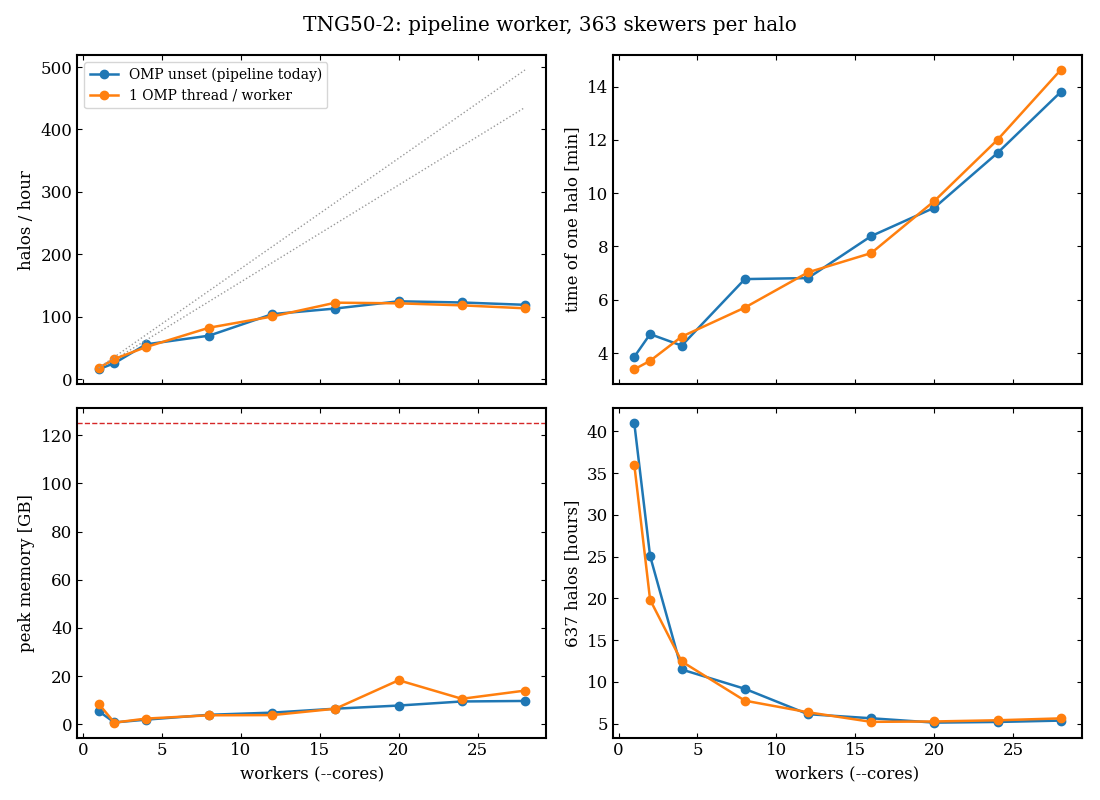

In [6]:
# ==============================================================================
# CELL 5: SCALING PLOTS
# ==============================================================================
label = {1: "1 OMP thread / worker", 0: "OMP unset (pipeline today)"}
fig, ax = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
ax = ax.ravel()

for omp, g in scan.groupby("omp"):
    kw = dict(marker="o", lw=1.8, label=label.get(omp, f"{omp} OMP threads"))
    ax[0].plot(g.n_workers, g.halos_per_hour, **kw)
    ax[1].plot(g.n_workers, g.halo_min_mean, **kw)
    ax[2].plot(g.n_workers, g.peak_mem_gb, **kw)
    ax[3].plot(g.n_workers, g.proj_637_hours, **kw)

    # Ideal scaling: N times the throughput of one worker
    one = g.loc[g.n_workers == 1, "halos_per_hour"]
    if len(one):
        ax[0].plot(g.n_workers, g.n_workers * one.iloc[0], ls=":", color="0.6", lw=1)

ax[0].set_ylabel("halos / hour")
ax[1].set_ylabel("time of one halo [min]")
ax[2].set_ylabel("peak memory [GB]")
ax[3].set_ylabel(f"{N_HALOS_PRODUCTION} halos [hours]")
ax[2].axhline(125, color="C3", ls="--", lw=1)          # RAM of the machine
for a in ax[2:]:
    a.set_xlabel("workers (--cores)")
ax[0].legend(fontsize=10)
fig.suptitle(f"{SIM_NAME}: pipeline worker, 363 skewers per halo")
fig.tight_layout()

# Best point of each OMP setting
for omp, g in scan.groupby("omp"):
    best = g.loc[g.halos_per_hour.idxmax()]
    print(f"{label.get(omp, omp):28s}: best N = {int(best.n_workers):2d}  ->  "
          f"{best.halos_per_hour:5.1f} halos/h, {best.proj_637_hours:4.1f} h per realization, "
          f"{best.peak_mem_gb:5.1f} GB")